In [ ]:
pip install ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo

heart_failure_clinical_records = fetch_ucirepo(id=519)

X = heart_failure_clinical_records.data.features
y = heart_failure_clinical_records.data.targets

print(heart_failure_clinical_records.metadata)


print(heart_failure_clinical_records.variables)


{'uci_id': 519, 'name': 'Heart Failure Clinical Records', 'repository_url': 'https://archive.ics.uci.edu/dataset/519/heart+failure+clinical+records', 'data_url': 'https://archive.ics.uci.edu/static/public/519/data.csv', 'abstract': 'This dataset contains the medical records of 299 patients who had heart failure, collected during their follow-up period, where each patient profile has 13 clinical features.', 'area': 'Health and Medicine', 'tasks': ['Classification', 'Regression', 'Clustering'], 'characteristics': ['Multivariate'], 'num_instances': 299, 'num_features': 12, 'feature_types': ['Integer', 'Real'], 'demographics': ['Age', 'Sex'], 'target_col': ['death_event'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2020, 'last_updated': 'Mon Feb 26 2024', 'dataset_doi': '10.24432/C5Z89R', 'creators': [], 'intro_paper': {'ID': 286, 'type': 'NATIVE', 'title': 'Machine learning can predict survival of patients with heart failure f

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from sklearn.decomposition import PCA

RANDOM_STATE = 42
N_INIT = 10
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [ ]:
try:
    from ucimlrepo import fetch_ucirepo
    hf = fetch_ucirepo(id=519)
    df = pd.concat([hf.data.features, hf.data.targets], axis=1)
    print("Dados carregados")
except Exception as erro:
    print(f"ucimlrepo indisponível ({erro}); lendo o CSV")
    df = pd.read_csv("heart_failure_clinical_records_dataset.csv")

df.columns = df.columns.str.lower()
print("Formato:", df.shape)
df.head()

Dados carregados
Formato: (299, 13)


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,death_event
0,75.00,0,582,0,20,1,"265,000.00",1.90,130,1,0,4,1
1,55.00,0,7861,0,38,0,"263,358.03",1.10,136,1,0,6,1
2,65.00,0,146,0,20,0,"162,000.00",1.30,129,1,1,7,1
3,50.00,1,111,0,20,0,"210,000.00",1.90,137,1,0,7,1
4,65.00,1,160,1,20,0,"327,000.00",2.70,116,0,0,8,1


In [ ]:
atributos = pd.DataFrame([
    ("age",                      "Idade do paciente",                              "anos",             "inteiro",  "usado"),
    ("anaemia",                  "Redução de hemácias ou hemoglobina",             "0 = não, 1 = sim", "binário",  "descritivo"),
    ("creatinine_phosphokinase", "Nível da enzima CPK no sangue",                  "mcg/L",            "inteiro",  "usado (log)"),
    ("diabetes",                 "Paciente tem diabetes",                          "0 = não, 1 = sim", "binário",  "descritivo"),
    ("ejection_fraction",        "% de sangue que sai do coração a cada contração","%",                "inteiro",  "usado"),
    ("high_blood_pressure",      "Paciente tem hipertensão",                       "0 = não, 1 = sim", "binário",  "descritivo"),
    ("platelets",                "Plaquetas no sangue",                            "kiloplatelets/mL", "contínuo", "usado"),
    ("serum_creatinine",         "Creatinina sérica (função renal)",               "mg/dL",            "contínuo", "usado (log)"),
    ("serum_sodium",             "Sódio sérico",                                   "mEq/L",            "inteiro",  "usado"),
    ("sex",                      "Sexo",                                           "0 = mulher, 1 = homem", "binário", "descritivo"),
    ("smoking",                  "Paciente fuma",                                  "0 = não, 1 = sim", "binário",  "descritivo"),
    ("time",                     "Duração do acompanhamento",                      "dias",             "inteiro",  "excluído"),
    ("death_event",              "Paciente morreu durante o acompanhamento",       "0 = não, 1 = sim", "rótulo",   "excluído (só verificação)"),
], columns=["atributo", "descrição", "unidade", "tipo", "uso no K-means"])
atributos

,atributo,descrição,unidade,tipo,uso no K-means
0,age,Idade do paciente,anos,inteiro,usado
1,anaemia,Redução de hemácias ou hemoglobina,"0 = não, 1 = sim",binário,descritivo
2,creatinine_phosphokinase,Nível da enzima CPK no sangue,mcg/L,inteiro,usado (log)
3,diabetes,Paciente tem diabetes,"0 = não, 1 = sim",binário,descritivo
4,ejection_fraction,% de sangue que sai do coração a cada contração,%,inteiro,usado
5,high_blood_pressure,Paciente tem hipertensão,"0 = não, 1 = sim",binário,descritivo
6,platelets,Plaquetas no sangue,kiloplatelets/mL,contínuo,usado
7,serum_creatinine,Creatinina sérica (função renal),mg/dL,contínuo,usado (log)
8,serum_sodium,Sódio sérico,mEq/L,inteiro,usado
9,sex,Sexo,"0 = mulher, 1 = homem",binário,descritivo


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,299.00,60.83,11.89,40.00,51.00,60.00,70.00,95.00
anaemia,299.00,0.43,0.50,0.00,0.00,0.00,1.00,1.00
creatinine_phosphokinase,299.00,581.84,970.29,23.00,116.50,250.00,582.00,"7,861.00"
diabetes,299.00,0.42,0.49,0.00,0.00,0.00,1.00,1.00
ejection_fraction,299.00,38.08,11.83,14.00,30.00,38.00,45.00,80.00
high_blood_pressure,299.00,0.35,0.48,0.00,0.00,0.00,1.00,1.00
platelets,299.00,"263,358.03","97,804.24","25,100.00","212,500.00","262,000.00","303,500.00","850,000.00"
serum_creatinine,299.00,1.39,1.03,0.50,0.90,1.10,1.40,9.40
serum_sodium,299.00,136.63,4.41,113.00,134.00,137.00,140.00,148.00
sex,299.00,0.65,0.48,0.00,0.00,1.00,1.00,1.00


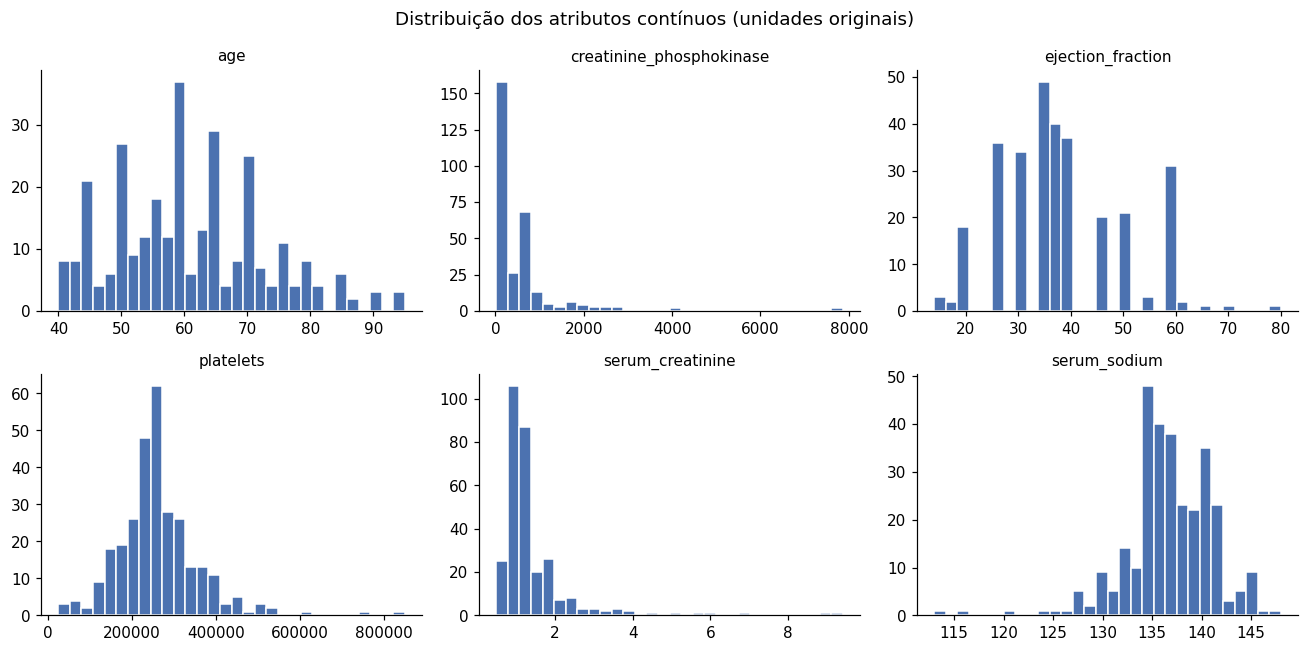

Assimetria (skewness): valores acima de ~1 indicam cauda longa à direita
age                         0.42
creatinine_phosphokinase    4.46
ejection_fraction           0.56
platelets                   1.46
serum_creatinine            4.46
serum_sodium               -1.05
dtype: float64


In [ ]:
CONTINUAS = ["age", "creatinine_phosphokinase", "ejection_fraction",
             "platelets", "serum_creatinine", "serum_sodium"]

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, c in zip(axes.ravel(), CONTINUAS):
    ax.hist(df[c], bins=30, color="#4C72B0", edgecolor="white")
    ax.set_title(c, fontsize=10)
fig.suptitle("Distribuição dos atributos contínuos (unidades originais)")
fig.tight_layout()
plt.show()

print("Assimetria (skewness): valores acima de ~1 indicam cauda longa à direita")
print(df[CONTINUAS].skew().round(2))

In [ ]:
print("Valores ausentes:")
print(df.isna().sum().to_string())
print("\nLinhas duplicadas:", df.duplicated().sum())

Valores ausentes:
age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
death_event                 0

Linhas duplicadas: 0


In [ ]:
y = df["death_event"].copy()
BINARIAS = ["anaemia", "diabetes", "high_blood_pressure", "sex", "smoking"]
LOG_COLS = ["creatinine_phosphokinase", "serum_creatinine"]

X_orig = df[CONTINUAS].copy()
X_log = X_orig.copy()
for c in LOG_COLS:
    X_log[c] = np.log(X_log[c])

scaler = StandardScaler()
Z = scaler.fit_transform(X_log)
X = pd.DataFrame(Z, columns=CONTINUAS)

n, d = X.shape
print(f"Matriz X final: n = {n} pacientes × d = {d} atributos")

Matriz X final: n = 299 pacientes × d = 6 atributos


In [ ]:
exemplo = pd.concat(
    {"1. original": X_orig.head(3), "2. após log": X_log.head(3), "3. padronizado (z)": X.head(3)},
    axis=1).T
exemplo

0          1          2
1. original        age                           75.00      55.00      65.00
                   creatinine_phosphokinase     582.00   7,861.00     146.00
                   ejection_fraction             20.00      38.00      20.00
                   platelets                265,000.00 263,358.03 162,000.00
                   serum_creatinine               1.90       1.10       1.30
                   serum_sodium                 130.00     136.00     129.00
2. após log        age                           75.00      55.00      65.00
                   creatinine_phosphokinase       6.37       8.97       4.98
                   ejection_fraction             20.00      38.00      20.00
                   platelets                265,000.00 263,358.03 162,000.00
                   serum_creatinine               0.64       0.10       0.26
                   serum_sodium                 130.00     136.00     129.00
3. padronizado (z) age                            1.19      -0.49       0.35
                   creatinine_phosphokinase       0.62       2.92      -0.60
                   ejection_fraction             -1.53      -0.01      -1.53
                   platelets                      0.02       0.00      -1.04
                   serum_creatinine               0.98      -0.23       0.14
                   serum_sodium                  -1.50      -0.14      -1.73

In [ ]:
pd.DataFrame({"média antes": X_log.mean(), "desvio antes": X_log.std(ddof=0),
              "média depois": X.mean(), "desvio depois": X.std(ddof=0)})

,média antes,desvio antes,média depois,desvio depois
age,60.83,11.87,0.00,1.00
creatinine_phosphokinase,5.66,1.13,0.00,1.00
ejection_fraction,38.08,11.82,-0.00,1.00
platelets,"263,358.03","97,640.55",0.00,1.00
serum_creatinine,0.20,0.45,-0.00,1.00
serum_sodium,136.63,4.41,-0.00,1.00


In [ ]:
modelos, J = {}, {}
for k in range(1, 11):
    km = KMeans(n_clusters=k, init="k-means++", n_init=N_INIT, random_state=RANDOM_STATE)
    km.fit(X)
    modelos[k] = km
    J[k] = km.inertia_

pd.DataFrame({"J final (inércia)": J,
              "iterações até convergir": {k: m.n_iter_ for k, m in modelos.items()}}).rename_axis("k")

,J final (inércia),iterações até convergir
k,,
1,"1,794.00",2
2,"1,514.45",14
3,"1,336.30",21
4,"1,208.76",20
5,"1,104.73",32
6,"1,021.16",19
7,946.97,12
8,899.16,15
9,873.74,16


---
## Etapa 4 — Escolher k

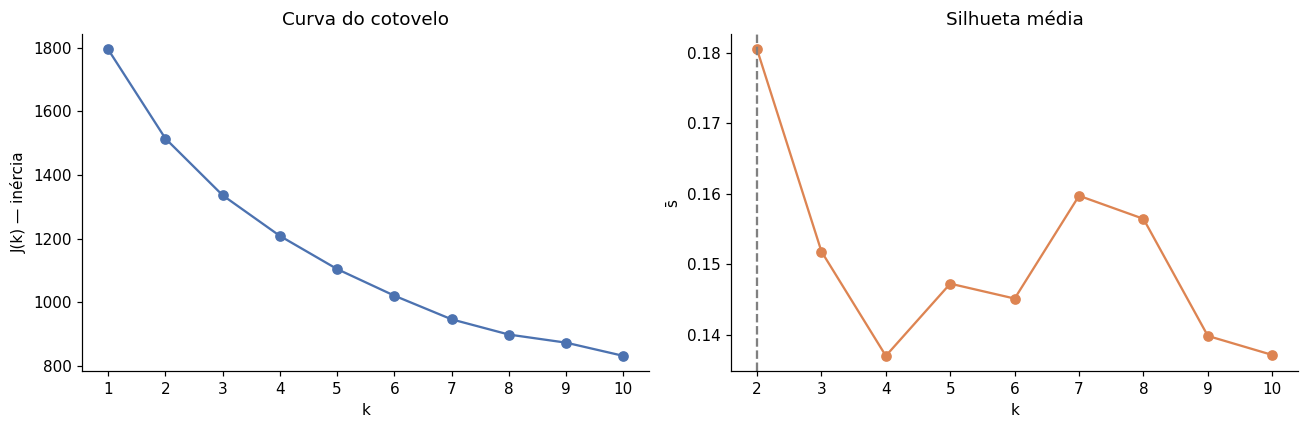

,J(k),queda de J (%),s̄
k,,,
1,"1,794.00",NaN,NaN
2,"1,514.45",15.58,0.18
3,"1,336.30",11.76,0.15
4,"1,208.76",9.54,0.14
5,"1,104.73",8.61,0.15
6,"1,021.16",7.56,0.15
7,946.97,7.27,0.16
8,899.16,5.05,0.16
9,873.74,2.83,0.14


In [ ]:
s_media = {k: silhouette_score(X, modelos[k].labels_) for k in range(2, 11)}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(list(J), list(J.values()), "o-", color="#4C72B0")
ax1.set(title="Curva do cotovelo", xlabel="k", ylabel="J(k) — inércia", xticks=range(1, 11))
ax2.plot(list(s_media), list(s_media.values()), "o-", color="#DD8452")
ax2.set(title="Silhueta média", xlabel="k", ylabel="s̄", xticks=range(2, 11))
k_melhor_s = max(s_media, key=s_media.get)
ax2.axvline(k_melhor_s, ls="--", color="gray")
fig.tight_layout()
plt.show()

tabela_k = pd.DataFrame({"J(k)": J, "queda de J (%)": pd.Series(J).pct_change().mul(-100), "s̄": s_media})
tabela_k.rename_axis("k")

In [ ]:
K_ESCOLHIDO = 2
VIZINHOS = [3, 4]

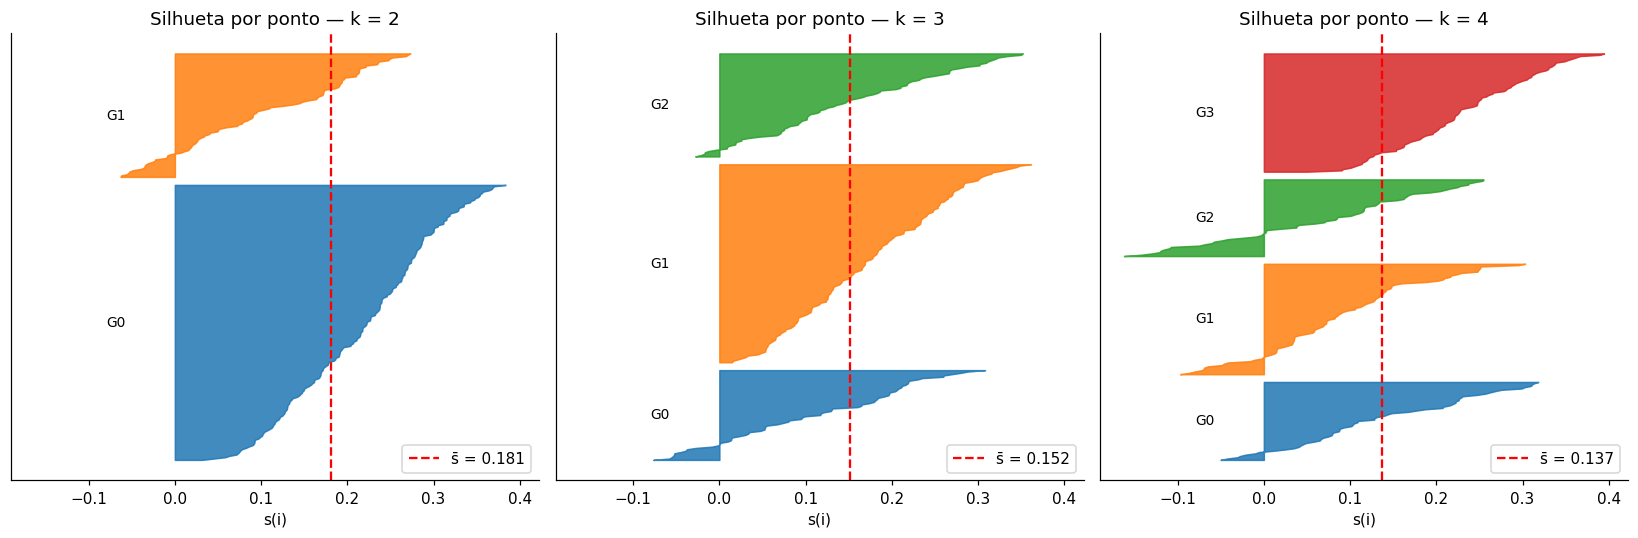

tamanho  s̄ do grupo  pontos com s < 0
k grupo                                        
2 G0         206         0.22                 0
  G1          93         0.10                18
3 G0          69         0.11                12
  G1         151         0.17                 0
  G2          79         0.15                 6
4 G0          61         0.13                 7
  G1          86         0.09                14
  G2          60         0.07                18
  G3          92         0.23                 0

In [ ]:
def grafico_silhueta(k, ax):
    rotulos = modelos[k].labels_
    s = silhouette_samples(X, rotulos)
    cores = plt.cm.tab10.colors
    y0 = 0
    for g in range(k):
        sg = np.sort(s[rotulos == g])
        ax.fill_betweenx(np.arange(y0, y0 + len(sg)), 0, sg, color=cores[g % 10], alpha=0.85)
        ax.text(-0.08, y0 + len(sg) / 2, f"G{g}", va="center", fontsize=9)
        y0 += len(sg) + 5
    ax.axvline(s.mean(), color="red", ls="--", label=f"s̄ = {s.mean():.3f}")
    ax.set(title=f"Silhueta por ponto — k = {k}", xlabel="s(i)", yticks=[])
    ax.legend(loc="lower right")
    return s

ks = sorted([K_ESCOLHIDO] + VIZINHOS)
fig, axes = plt.subplots(1, len(ks), figsize=(5 * len(ks), 5), sharex=True)
resumo = []
for ax, k in zip(np.atleast_1d(axes), ks):
    s = grafico_silhueta(k, ax)
    for g in range(k):
        sg = s[modelos[k].labels_ == g]
        resumo.append({"k": k, "grupo": f"G{g}", "tamanho": len(sg), "s̄ do grupo": sg.mean(),
                       "pontos com s < 0": int((sg < 0).sum())})
fig.tight_layout()
plt.show()

pd.DataFrame(resumo).set_index(["k", "grupo"])

In [ ]:
km_final = modelos[K_ESCOLHIDO]
grupo = pd.Series(km_final.labels_, name="grupo")

centroides = pd.DataFrame(scaler.inverse_transform(km_final.cluster_centers_), columns=CONTINUAS)
for c in LOG_COLS:
    centroides[c] = np.exp(centroides[c])
centroides.index = [f"G{g}" for g in range(K_ESCOLHIDO)]
centroides.insert(0, "|C_k|", grupo.value_counts().sort_index().values)

media_geral = X_orig.mean().rename("média geral")
tabela_centroides = pd.concat([centroides, media_geral.to_frame().T])
tabela_centroides

,|C_k|,age,creatinine_phosphokinase,ejection_fraction,platelets,serum_creatinine,serum_sodium
G0,206.00,57.66,297.52,40.28,"272,973.16",1.01,138.20
G1,93.00,67.87,265.35,33.22,"242,060.00",1.86,133.14
média geral,NaN,60.83,581.84,38.08,"263,358.03",1.39,136.63


In [ ]:
df_g = df.assign(grupo=[f"G{g}" for g in grupo])
medianas = df_g.groupby("grupo")[CONTINUAS].median()
binarios = df_g.groupby("grupo")[BINARIAS].mean().mul(100).add_suffix(" (%)")
pd.concat([medianas, binarios], axis=1)

,age,creatinine_phosphokinase,ejection_fraction,platelets,serum_creatinine,serum_sodium,anaemia (%),diabetes (%),high_blood_pressure (%),sex (%),smoking (%)
grupo,,,,,,,,,,,
G0,58.00,251.50,38.00,"263,358.03",1.00,138.00,44.66,41.75,35.92,62.14,33.50
G1,68.00,246.00,35.00,"243,000.00",1.80,134.00,39.78,41.94,33.33,70.97,29.03


G0 (206 pacientes)  ALTO: —  |  BAIXO: —
G1 (93 pacientes)  ALTO: age, serum_creatinine  |  BAIXO: serum_sodium


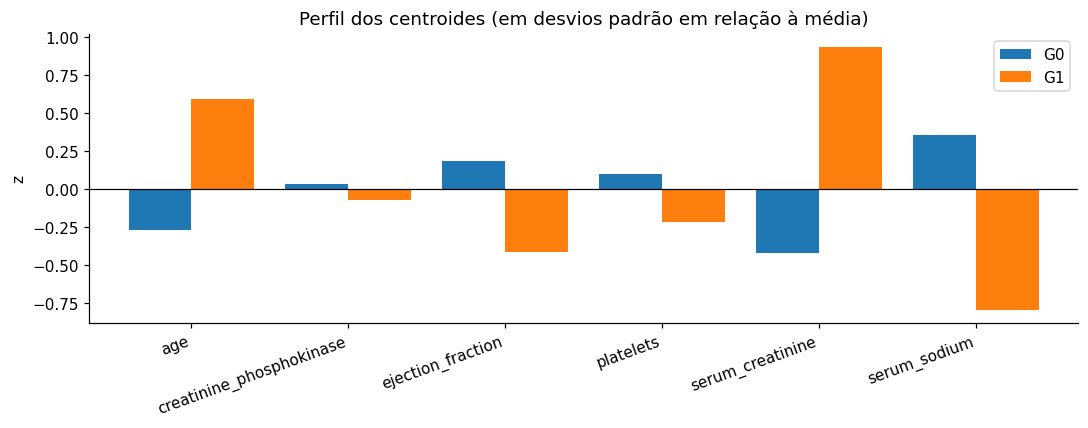

In [ ]:
z_cent = pd.DataFrame(km_final.cluster_centers_, columns=CONTINUAS,
                      index=[f"G{g}" for g in range(K_ESCOLHIDO)])
for g, linha in z_cent.iterrows():
    altos = [c for c, v in linha.items() if v > 0.5]
    baixos = [c for c, v in linha.items() if v < -0.5]
    print(f"{g} ({(grupo == int(g[1:])).sum()} pacientes)  ALTO: {', '.join(altos) or '—'}  |  BAIXO: {', '.join(baixos) or '—'}")

ax = z_cent.T.plot(kind="bar", figsize=(10, 4), width=0.8)
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Perfil dos centroides (em desvios padrão em relação à média)", ylabel="z")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

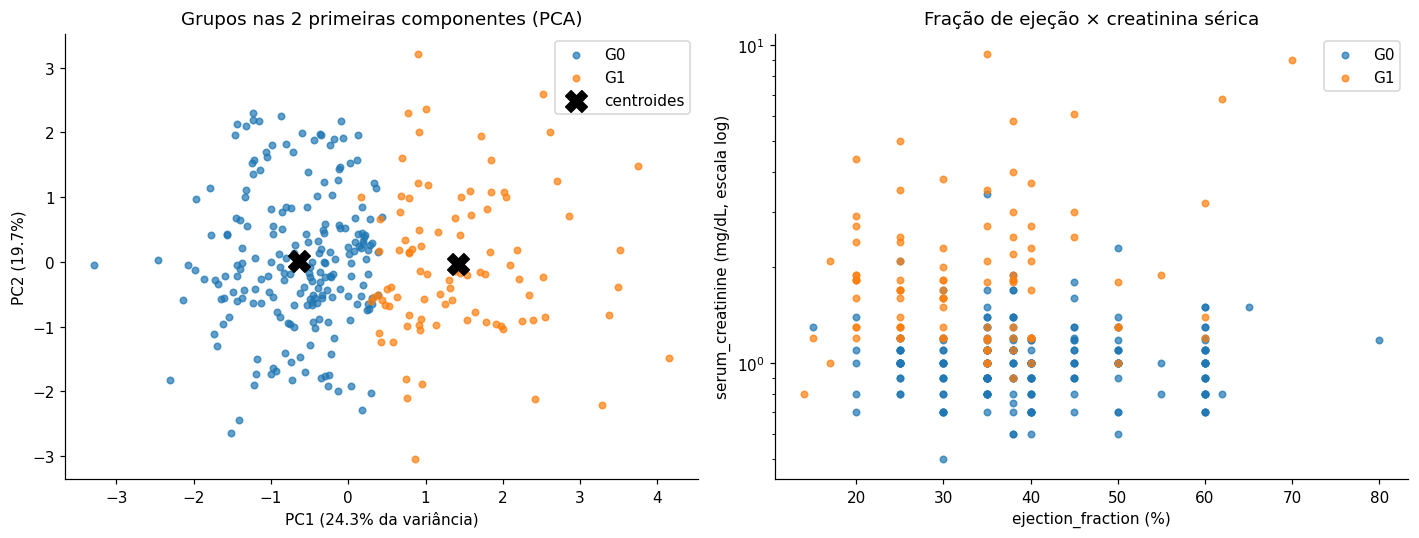

Cargas das componentes (o que cada eixo do PCA representa):


,PC1,PC2
age,0.39,0.52
creatinine_phosphokinase,-0.16,-0.51
ejection_fraction,-0.31,0.61
platelets,-0.24,0.09
serum_creatinine,0.62,0.11
serum_sodium,-0.54,0.27


In [ ]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
P = pca.fit_transform(X.values)
C = pca.transform(km_final.cluster_centers_)
cores = plt.cm.tab10.colors

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
for g in range(K_ESCOLHIDO):
    m = grupo == g
    ax1.scatter(P[m, 0], P[m, 1], s=18, alpha=0.7, color=cores[g], label=f"G{g}")
    ax2.scatter(X_orig.loc[m, "ejection_fraction"], X_orig.loc[m, "serum_creatinine"],
                s=18, alpha=0.7, color=cores[g], label=f"G{g}")
ax1.scatter(C[:, 0], C[:, 1], marker="X", s=200, color="black", label="centroides")
v = pca.explained_variance_ratio_ * 100
ax1.set(title="Grupos nas 2 primeiras componentes (PCA)",
        xlabel=f"PC1 ({v[0]:.1f}% da variância)", ylabel=f"PC2 ({v[1]:.1f}%)")
ax2.set(title="Fração de ejeção × creatinina sérica", xlabel="ejection_fraction (%)",
        ylabel="serum_creatinine (mg/dL, escala log)", yscale="log")
ax1.legend(); ax2.legend()
fig.tight_layout()
plt.show()

print("Cargas das componentes (o que cada eixo do PCA representa):")
pd.DataFrame(pca.components_.T, index=CONTINUAS, columns=["PC1", "PC2"]).round(2)

In [ ]:
def silhueta_config(matriz):
    m = StandardScaler().fit_transform(matriz)
    r = KMeans(n_clusters=K_ESCOLHIDO, init="k-means++", n_init=N_INIT, random_state=RANDOM_STATE).fit_predict(m)
    return silhouette_score(m, r), r

s_final = s_media[K_ESCOLHIDO]
s_sem_log, r_sem_log = silhueta_config(X_orig)
s_bin, r_bin = silhueta_config(pd.concat([X_log, df[BINARIAS]], axis=1))
pd.DataFrame({
    "silhueta média": [s_final, s_sem_log, s_bin],
    "concordância com a versão final (ARI)": [1.0, adjusted_rand_score(grupo, r_sem_log),
                                              adjusted_rand_score(grupo, r_bin)],
}, index=["final (6 contínuos, com log)", "sem transformação log", "com os 5 binários"])

,silhueta média,concordância com a versão final (ARI)
"final (6 contínuos, com log)",0.18,1.00
sem transformação log,0.15,0.41
com os 5 binários,0.12,-0.01


In [ ]:
def contar_outliers(tabela):
    q1 = tabela.quantile(0.25)
    q3 = tabela.quantile(0.75)
    iqr = q3 - q1
    fora = (tabela < q1 - 1.5 * iqr) | (tabela > q3 + 1.5 * iqr)
    return fora.sum()

pd.DataFrame({"outliers sem log": contar_outliers(X_orig),
              "outliers com log": contar_outliers(X_log)})

,outliers sem log,outliers com log
age,0,0
creatinine_phosphokinase,29,2
ejection_fraction,2,2
platelets,21,21
serum_creatinine,29,17
serum_sodium,4,4


In [ ]:
tab = pd.crosstab(df_g["grupo"], y.map({0: "sobreviveu", 1: "morreu"}), margins=True, margins_name="total")
tab["mortalidade (%)"] = 100 * tab["morreu"] / tab["total"]
print(f"Mortalidade geral: {100 * y.mean():.1f}%")
print(f"ARI entre grupos e óbito: {adjusted_rand_score(y, grupo):.3f}  (0 = sem relação, 1 = idêntico)")
tab

Mortalidade geral: 32.1%
ARI entre grupos e óbito: 0.219  (0 = sem relação, 1 = idêntico)


death_event,morreu,sobreviveu,total,mortalidade (%)
grupo,,,,
G0,40,166,206,19.42
G1,56,37,93,60.22
total,96,203,299,32.11
